# 04. Риск портфеля: $\sigma_p = \sqrt{w^\top\Sigma w}$

Два вопроса: **сколько** риска в портфеле и **откуда** он берётся — по активам и по факторам PCA.
Риск в деньгах считаем по **ковариационной** матрице (годовой: дневная × 252) — «громкость» активов здесь настоящий риск.

In [1]:
import sys; sys.path.append('..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.precision', 3)
from src.data import *
from src.risk import *
from src.pca import *
from src.plots import *

In [2]:
r = simple_returns(clean_prices(load_prices()))
S = covariance_matrix(r) * TRADING_DAYS
stocks = TICKERS[:25]
tech, rest = UNIVERSE['Tech'], [t for t in TICKERS if t not in UNIVERSE['Tech']]

portfolios = {
    'EW27':       pd.Series(1 / 27, index=TICKERS),
    'EW stocks':  pd.Series(1 / 25, index=stocks),
    '60/40':      pd.concat([pd.Series(0.6 / 25, index=stocks), pd.Series({'TLT': 0.4})]),
    'Tech heavy': pd.concat([pd.Series(0.5 / 5, index=tech), pd.Series(0.5 / 22, index=rest)]),
}

## 1. Формула против реального ряда
Если формула верна, $\sqrt{w^\top\Sigma w}$ должна совпасть с волатильностью ряда $r_p = Rw$ — без моделирования портфеля день за днём.

In [3]:
pd.DataFrame({
    'по формуле, %': {n: portfolio_vol(w, S) * 100 for n, w in portfolios.items()},
    'реальный ряд, %': {n: (r[w.index] @ w).std() * np.sqrt(TRADING_DAYS) * 100 for n, w in portfolios.items()},
}).round(2)

,"по формуле, %","реальный ряд, %"
EW27,13.59,13.59
EW stocks,14.53,14.53
60/40,10.80,10.80
Tech heavy,17.49,17.49


## 2. Вклад каждого актива
Предельный риск — производная $\dfrac{\partial\sigma_p}{\partial w_i} = \dfrac{(\Sigma w)_i}{\sigma_p}$. Вклад актива:
$$\text{RC}_i = w_i\frac{(\Sigma w)_i}{\sigma_p} = w_i\,\sigma_i\,\rho_{i,p}, \qquad \sum_i \text{RC}_i = \sigma_p$$
Вес × громкость × корреляция с портфелем.

In [4]:
w = portfolios['EW27']
rc = risk_contributions(w, S)
rp = r @ w
alt = w * r.std() * np.sqrt(TRADING_DAYS) * r.corrwith(rp)
print('сумма вкладов = σ_p:', np.isclose(rc.contrib.sum(), portfolio_vol(w, S)))
print('RC = w·σ·ρ:', np.allclose(rc.contrib, alt))
(rc.assign(sigma=r.std() * np.sqrt(TRADING_DAYS), rho_p=r.corrwith(rp))
   .loc[['NVDA', 'SLB', 'MS', 'KO', 'TLT', 'GLD'], ['weight', 'sigma', 'rho_p', 'share']] * [100, 100, 1, 100]).round(2)

сумма вкладов = σ_p: True
RC = w·σ·ρ: True


,weight,sigma,rho_p,share
NVDA,3.7,51.99,0.52,7.39
SLB,3.7,37.54,0.59,6.03
MS,3.7,28.86,0.71,5.57
KO,3.7,16.67,0.39,1.78
TLT,3.7,15.69,0.06,0.27
GLD,3.7,18.91,0.19,1.00


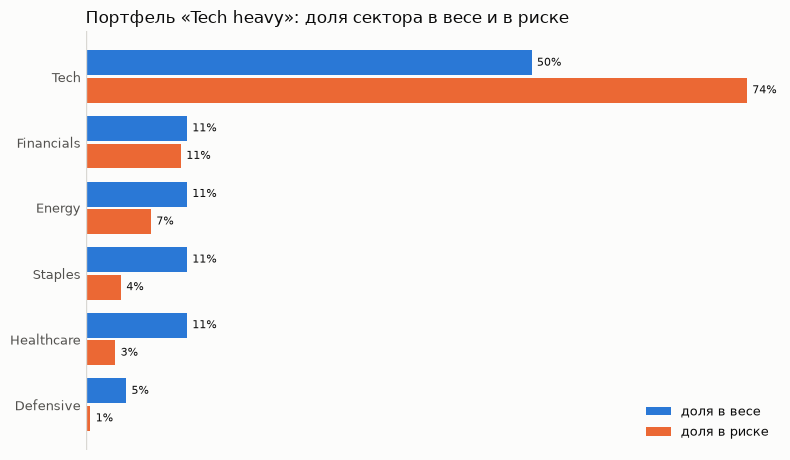

In [5]:
by_sector = risk_contributions(portfolios['Tech heavy'], S).groupby(pd.Series(SECTOR_OF))[['weight', 'share']].sum()
weight_vs_risk(by_sector, 'Портфель «Tech heavy»: доля сектора в весе и в риске');

**Половина денег — три четверти риска:** техи громкие и сильно связаны между собой, их вклады складываются.

### Предельный риск как инструмент
Переложить долю $\Delta$ из актива A в B: $\Delta\sigma_p \approx \Delta\,(\text{marginal}_B - \text{marginal}_A)$.

In [6]:
wt = portfolios['Tech heavy']
m = risk_contributions(wt, S).marginal
base = portfolio_vol(wt, S)
for to in ['MSFT', 'TLT']:
    w2 = wt.copy(); w2['NVDA'] -= 0.05; w2[to] += 0.05
    print(f'5% NVDA → {to}: факт {portfolio_vol(w2, S) - base:+.2%}, оценка {0.05 * (m[to] - m["NVDA"]):+.2%}')

5% NVDA → MSFT: факт -0.81%, оценка -0.93%
5% NVDA → TLT: факт -1.80%, оценка -1.92%


## 3. Вклад факторов PCA
Подставим $\Sigma = Q\Lambda Q^\top$:
$$w^\top\Sigma w = (Q^\top w)^\top\Lambda\,(Q^\top w) = \sum_k \lambda_k\,(q_k^\top w)^2$$
$q_k^\top w$ — экспозиция портфеля на фактор $k$; факторы не коррелируют, поэтому их дисперсии просто складываются.

In [7]:
lam, Q = pca(S)
shares = pd.DataFrame({n: factor_risk(w, lam, Q).share for n, w in portfolios.items()}).T * 100
shares[['PC1', 'PC2', 'PC3', 'PC4']].assign(**{'PC5–PC27': shares.iloc[:, 4:].sum(axis=1)}).round(1)

,PC1,PC2,PC3,PC4,PC5–PC27
EW27,90.0,1.8,5.2,2.4,0.7
EW stocks,90.5,2.0,5.1,2.1,0.3
60/40,57.3,0.1,7.2,3.9,31.5
Tech heavy,88.2,6.7,0.1,3.7,1.3


**Иллюзия диверсификации:** в портфеле из 27 активов ≈90% риска — одна ставка на рынок (PC1).

In [8]:
k = Q.loc['TLT'].abs().idxmax()
print(f'TLT сильнее всего входит в {k} (вес {Q.loc["TLT", k]:.2f})')
print(f'{k} объясняет {lam[k] / lam.sum():.1%} общей дисперсии рынка,')
print(f'но {factor_risk(portfolios["60/40"], lam, Q).loc[k, "share"]:.1%} риска портфеля 60/40')

TLT сильнее всего входит в PC18 (вес 0.68)
PC18 объясняет 0.9% общей дисперсии рынка,
но 12.8% риска портфеля 60/40


**Вывод для отчёта:** «маленький» для рынка фактор может быть крупным для конкретного портфеля — отбрасывать младшие компоненты без проверки нельзя.